In [36]:
import numpy as np
import pandas as pd  
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Part 1

# 1. Dataset Loading (Dataset-1)

In [37]:
# 1. SET YOUR FILE PATH AND COLUMN NAMES
file_path_1 = 'dataset-1.csv' 
feature_cols = ['Feature_1', 'Feature_2'] 
label_col = 'Class'                     

# 2. LOAD THE DATA
try:
    data1 = pd.read_csv(file_path_1)
    X_linear = data1[feature_cols].values
    y_linear_original = data1[label_col].values
    print(f"Successfully loaded {file_path_1}")
except FileNotFoundError:
    print(f"Error: File not found at '{file_path_1}'")
    print("Please update the 'file_path_1' variable to your dataset's location.")
    # As a fallback, we'll create data so the rest of the script can run
    from sklearn.datasets import make_blobs
    X_linear, y_linear_original = make_blobs(n_samples=100, centers=2, random_state=42)
    print("Using fallback data for demonstration.")


# 3. CONVERT LABELS TO -1 AND 1
# This is a *crucial* step for the SVM hinge loss calculation.
# We'll assume the original labels are {0, 1} or {1, 2} etc.
# This code converts the lower class to -1 and the higher class to 1.
unique_labels = np.unique(y_linear_original)
if len(unique_labels) != 2:
    print(f"Warning: Expected 2 classes, found {len(unique_labels)}. SVM may not work as expected.")
else:
    print(f"Original labels found: {unique_labels}. Converting to {-1, 1}.")
    y_linear = np.where(y_linear_original == unique_labels[0], -1, 1)

print(f"Dataset-1 shape: X={X_linear.shape}, y={y_linear.shape}")

Successfully loaded dataset-1.csv
Original labels found: [-1  1]. Converting to (-1, 1).
Dataset-1 shape: X=(200, 2), y=(200,)


# 2. Initial Visualization (Dataset-1)

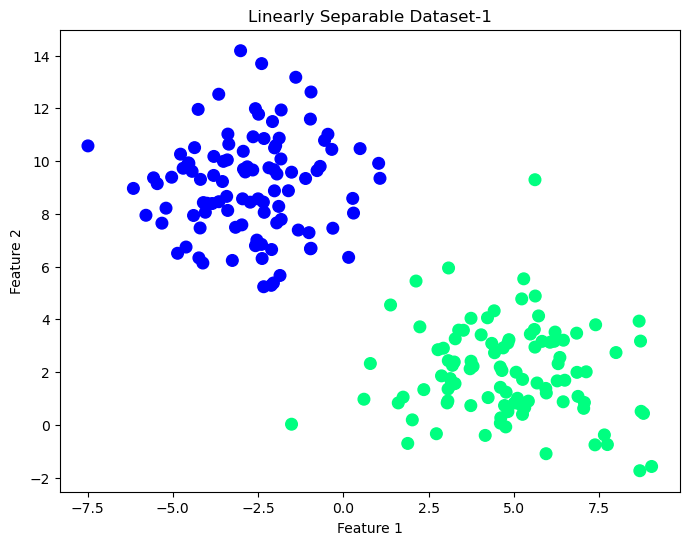

In [38]:
plt.figure(figsize=(8, 6))
plt.scatter(X_linear[:, 0], X_linear[:, 1], c=y_linear, cmap='winter', s=70)
plt.title("Linearly Separable Dataset-1")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Data Splitting

In [39]:
X_train_lin, X_test_lin, y_train_lin, y_test_lin = train_test_split(
    X_linear, y_linear, test_size=0.2, random_state=42
)

print(f"Training samples: {len(X_train_lin)}")
print(f"Testing samples: {len(X_test_lin)}")

Training samples: 160
Testing samples: 40


# 4. SVM Algorithm Implementation (from scratch)

In [40]:
class SVM:
    """
    A simple Support Vector Machine classifier implemented from scratch
    using Gradient Descent.
    """

    def __init__(self, learning_rate=0.001, n_iters=1000, lambda_param=0.01):
        """
        Initialization of learning rate, iterations, and regularization param.
        """
        self.lr = learning_rate
        self.n_iters = n_iters
        self.lambda_param = lambda_param  # Regularization parameter
        self.w = None  # Weights
        self.b = None  # Bias

    def fit(self, X, y):
        """
        Fit method to train the SVM using gradient descent.
        """
        n_samples, n_features = X.shape

        # Initialize weights and bias
        self.w = np.random.randn(n_features) * 0.01
        self.b = 0

        # Gradient Descent loop
        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                # Check the condition: y_i * (w.x_i + b) >= 1
                condition = y[idx] * (np.dot(x_i, self.w) + self.b) >= 1

                if condition:
                    # Correctly classified, outside margin
                    dw = 2 * self.lambda_param * self.w
                    db = 0
                else:
                    # Misclassified OR correctly classified but within margin
                    dw = 2 * self.lambda_param * self.w - (y[idx] * x_i)
                    db = -y[idx]

                # Update rules for w and b
                self.w = self.w - self.lr * dw
                self.b = self.b - self.lr * db

    def predict(self, X):
        """
        Predict method to classify new data points.
        """
        linear_output = np.dot(X, self.w) + self.b
        return np.sign(linear_output)

# 5. Model Training

In [41]:
# Initialize and train the model
svm_linear = SVM(learning_rate=0.0001, n_iters=1000, lambda_param=0.01)
svm_linear.fit(X_train_lin, y_train_lin)

print("Training complete.")
print(f"Learned weights (w): {svm_linear.w}")
print(f"Learned bias (b): {svm_linear.b}")

Training complete.
Learned weights (w): [ 0.64312822 -0.22697371]
Learned bias (b): 0.43389999999996853


# 6. Visualization (Decision Boundary & Margins)

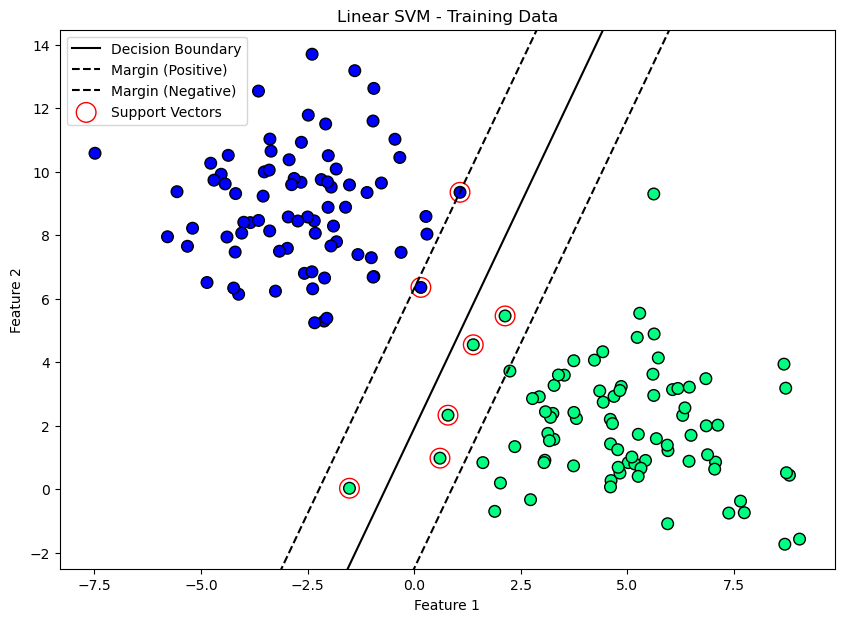

In [42]:
def visualize_svm(model, X, y, title="SVM Decision Boundary and Margins"):
    """Helper function to visualize the SVM boundary and margins."""
    
    plt.figure(figsize=(10, 7))
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=70, edgecolors='k')
    
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    xx = np.linspace(xlim[0], xlim[1], 30)
    yy = np.linspace(ylim[0], ylim[1], 30)
    YY, XX = np.meshgrid(yy, xx)
    
    w = model.w
    b = model.b
    
    if w[1] == 0: # Avoid division by zero
        w[1] = 1e-9

    def get_line_y(x, w, b, offset=0):
        return (-w[0] * x - b + offset) / w[1]

    decision_y = get_line_y(xx, w, b, 0)
    plt.plot(xx, decision_y, 'k-', label="Decision Boundary")

    margin_pos_y = get_line_y(xx, w, b, 1)
    plt.plot(xx, margin_pos_y, 'k--', label="Margin (Positive)")

    margin_neg_y = get_line_y(xx, w, b, -1)
    plt.plot(xx, margin_neg_y, 'k--', label="Margin (Negative)")

    decision_func = np.dot(X, w) + b
    support_vector_indices = np.where(np.abs(decision_func) <= 1 + 1e-5)[0]
    plt.scatter(X[support_vector_indices, 0], X[support_vector_indices, 1],
                s=200, facecolors='none', edgecolors='red',
                label="Support Vectors")

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.legend()
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    plt.show()

# Visualize the linear model
visualize_svm(svm_linear, X_train_lin, y_train_lin, title="Linear SVM - Training Data")

# 7. Model Testing

In [43]:
y_pred_train_lin = svm_linear.predict(X_train_lin)
train_accuracy_lin = accuracy_score(y_train_lin, y_pred_train_lin)

y_pred_test_lin = svm_linear.predict(X_test_lin)
test_accuracy_lin = accuracy_score(y_test_lin, y_pred_test_lin)

print(f"Accuracy on Training Set: {train_accuracy_lin * 100:.2f}%")
print(f"Accuracy on Testing Set: {test_accuracy_lin * 100:.2f}%")

Accuracy on Training Set: 99.38%
Accuracy on Testing Set: 100.00%


# Part 2

# 1. Dataset Loading 

In [44]:
# 1. SET YOUR FILE PATH AND COLUMN NAMES
file_path_2 = 'dataset-2.csv'  
feature_cols_2 = ['Feature_1', 'Feature_2'] 
label_col_2 = 'class'                     

# 2. LOAD THE DATA
try:
    data2 = pd.read_csv(file_path_2)
    X_nonlinear = data2[feature_cols_2].values
    y_nonlinear_original = data2[label_col_2].values
    print(f"Successfully loaded {file_path_2}")
except FileNotFoundError:
    print(f"Error: File not found at '{file_path_2}'")
    print("Please update the 'file_path_2' variable to your dataset's location.")
    # As a fallback, we'll create data so the rest of the script can run
    from sklearn.datasets import make_circles
    X_nonlinear, y_nonlinear_original = make_circles(n_samples=200, noise=0.1, factor=0.4, random_state=42)
    print("Using fallback data for demonstration.")

# 3. CONVERT LABELS TO -1 AND 1
unique_labels_2 = np.unique(y_nonlinear_original)
if len(unique_labels_2) != 2:
    print(f"Warning: Expected 2 classes, found {len(unique_labels_2)}. SVM may not work as expected.")
else:
    print(f"Original labels found: {unique_labels_2}. Converting to {-1, 1}.")
    y_nonlinear = np.where(y_nonlinear_original == unique_labels_2[0], -1, 1)

print(f"Dataset-2 shape: X={X_nonlinear.shape}, y={y_nonlinear.shape}")

Successfully loaded dataset-2.csv
Original labels found: [-1  1]. Converting to (-1, 1).
Dataset-2 shape: X=(300, 2), y=(300,)


# 2. Initial Visualization 

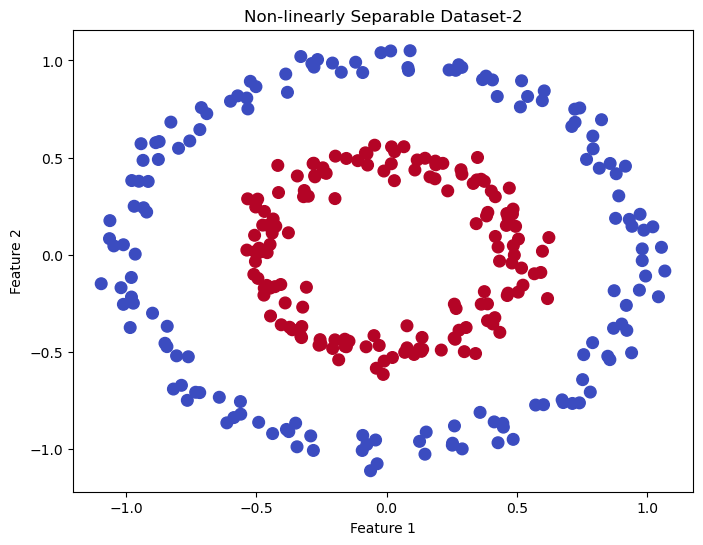

In [45]:
plt.figure(figsize=(8, 6))
plt.scatter(X_nonlinear[:, 0], X_nonlinear[:, 1], c=y_nonlinear, cmap='coolwarm', s=70)
plt.title("Non-linearly Separable Dataset-2")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Data Splitting

In [46]:
X_train_nonlin, X_test_nonlin, y_train_nonlin, y_test_nonlin = train_test_split(
    X_nonlinear, y_nonlinear, test_size=0.2, random_state=42
)

# 4. Feature Transformation (Kernel Trick Concept)

In [47]:
def feature_transform(X):
    """
    Transforms 2D data (x1, x2) into 3D data (x1, x2, x1^2 + x2^2).
    """
    if X.shape[1] != 2:
        raise ValueError("Input data must be 2-dimensional.")
    
    x1 = X[:, 0]
    x2 = X[:, 1]
    x3 = x1**2 + x2**2  # The new feature
    
    return np.c_[x1, x2, x3]

# Transform both training and testing data
X_train_3D = feature_transform(X_train_nonlin)
X_test_3D = feature_transform(X_test_nonlin)

print(f"Original training data shape: {X_train_nonlin.shape}")
print(f"Transformed training data shape: {X_train_3D.shape}")

Original training data shape: (240, 2)
Transformed training data shape: (240, 3)


# 5. SVM Algorithm Implementation (done above no need again)

# 6. Model Training

In [48]:
# Initialize and train the SVM on the 3D data
svm_nonlinear = SVM(learning_rate=0.001, n_iters=1000, lambda_param=0.01)
svm_nonlinear.fit(X_train_3D, y_train_nonlin)

print("Non-linear SVM training complete.")
print(f"Learned weights (w): {svm_nonlinear.w}")
print(f"Learned bias (b): {svm_nonlinear.b}")

Non-linear SVM training complete.
Learned weights (w): [-0.02212359  0.02157026 -3.14012017]
Learned bias (b): 1.8909999999999028


# 7. Visualization (3D and 2D)

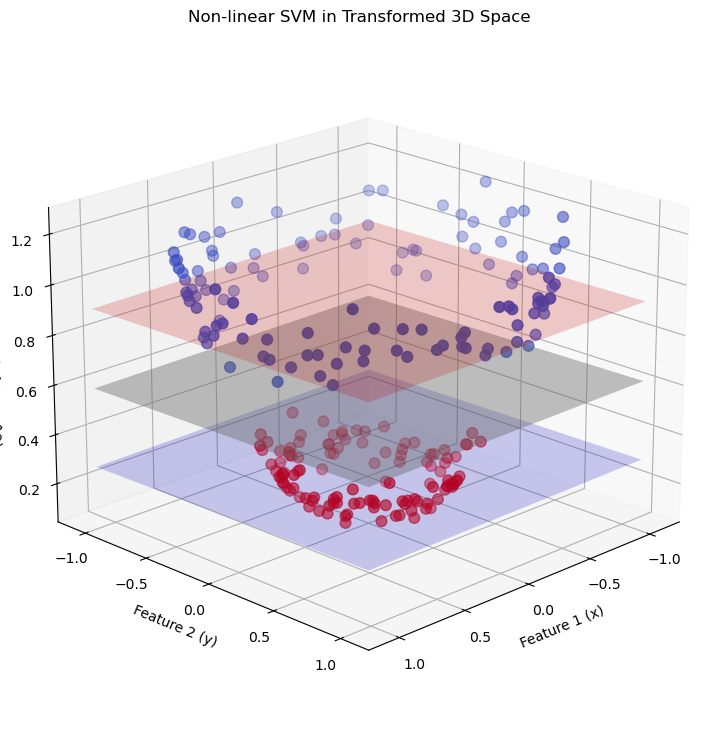

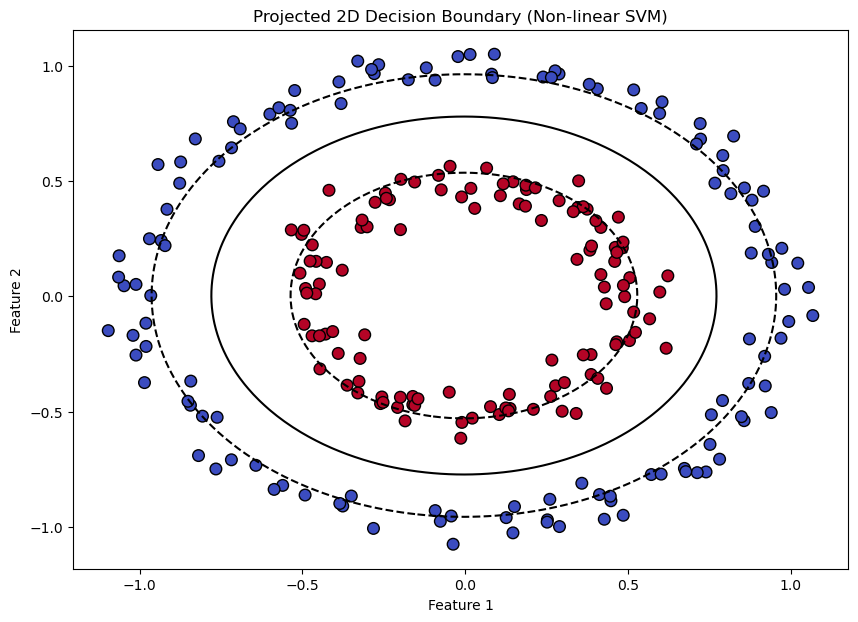

In [49]:
# 7a. 3D Visualization
w_3d = svm_nonlinear.w
b_3d = svm_nonlinear.b

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_train_3D[:, 0], X_train_3D[:, 1], X_train_3D[:, 2],
           c=y_train_nonlin, cmap='coolwarm', s=60, depthshade=True)

x_plane = np.linspace(np.min(X_train_3D[:, 0]), np.max(X_train_3D[:, 0]), 10)
y_plane = np.linspace(np.min(X_train_3D[:, 1]), np.max(X_train_3D[:, 1]), 10)
xx_plane, yy_plane = np.meshgrid(x_plane, y_plane)

if w_3d[2] == 0: # Avoid division by zero
    w_3d[2] = 1e-9

zz_plane = (-w_3d[0] * xx_plane - w_3d[1] * yy_plane - b_3d) / w_3d[2]
ax.plot_surface(xx_plane, yy_plane, zz_plane, alpha=0.4,
                rstride=100, cstride=100, color='gray')

zz_margin_pos = (-w_3d[0] * xx_plane - w_3d[1] * yy_plane - b_3d + 1) / w_3d[2]
ax.plot_surface(xx_plane, yy_plane, zz_margin_pos, alpha=0.2,
                rstride=100, cstride=100, color='blue')

zz_margin_neg = (-w_3d[0] * xx_plane - w_3d[1] * yy_plane - b_3d - 1) / w_3d[2]
ax.plot_surface(xx_plane, yy_plane, zz_margin_neg, alpha=0.2,
                rstride=100, cstride=100, color='red')

ax.view_init(elev=20, azim=45)
ax.set_title("Non-linear SVM in Transformed 3D Space")
ax.set_xlabel("Feature 1 (x)")
ax.set_ylabel("Feature 2 (y)")
ax.set_zlabel("Feature 3 (x^2 + y^2)")
plt.show()

# 7b. 2D Decision Boundary (Projected)
plt.figure(figsize=(10, 7))
plt.scatter(X_train_nonlin[:, 0], X_train_nonlin[:, 1],
            c=y_train_nonlin, cmap='coolwarm', s=70, edgecolors='k')

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()
xx = np.linspace(xlim[0], xlim[1], 100)
yy = np.linspace(ylim[0], ylim[1], 100)
XX, YY = np.meshgrid(xx, yy)

Z = (w_3d[0] * XX + w_3d[1] * YY +
     w_3d[2] * (XX**2 + YY**2) + b_3d)

plt.contour(XX, YY, Z, levels=[0], colors='k', linestyles=['-'])
plt.contour(XX, YY, Z, levels=[-1, 1], colors='k', linestyles=['--'])

plt.title("Projected 2D Decision Boundary (Non-linear SVM)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 8. Model Testing and Evaluation

In [50]:
# Predictions on transformed training data
y_pred_train_nonlin = svm_nonlinear.predict(X_train_3D)
train_accuracy_nonlin = accuracy_score(y_train_nonlin, y_pred_train_nonlin)

# Predictions on transformed testing data
y_pred_test_nonlin = svm_nonlinear.predict(X_test_3D)
test_accuracy_nonlin = accuracy_score(y_test_nonlin, y_pred_test_nonlin)

print(f"Accuracy on Transformed Training Set: {train_accuracy_nonlin * 100:.2f}%")
print(f"Accuracy on Transformed Testing Set: {test_accuracy_nonlin * 100:.2f}%")

Accuracy on Transformed Training Set: 100.00%
Accuracy on Transformed Testing Set: 100.00%
